# 07 · The proposal's protocol: evaluation on GQA val-balanced

**Purpose**: run the evaluation exactly as written in the proposal, alongside the testdev evaluation.
- **Stratified subsample of the balanced validation split** (2,500 questions), disjoint from the 500 calibration questions **and their images**.
- Same pipeline, same settings (`configs/default.yaml`), same benchmarks: greedy, majority vote (self-consistency), answer-only weighting, CW-MPVR; LXMERT as its **reported** accuracy (as proposed).
- Accuracy for **relational, logical, attribute, comparative** questions and **repeated CV (5 × 5-fold)**.

**Why both splits matter**: val images are Visual Genome images, seen during BLIP-2 pretraining; testdev images are new (notebook 04). Comparing the two directly tests whether CW-MPVR's gain depends on seen images.

**Runtime:** **L4 GPU**. Step 4 ≈ 70 min (resumable: if Colab disconnects, rerun Steps 1–4).


## 1 · Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys
REPO_DIR = "/content/drive/MyDrive/cw-mpvr"
%cd {REPO_DIR}
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)
!pip install -q datasets

from src.utils import load_config, set_seed, gpu_info
from src.gitsync import save_and_push
cfg = load_config()
set_seed(cfg["seed"])
SEED, GEN = cfg["seed"], cfg["generation"]
DATA, CACHE = cfg["paths"]["data"], cfg["paths"]["cache"]
print(gpu_info()); print("Generation settings:", GEN)

Mounted at /content/drive
/content/drive/MyDrive/cw-mpvr
NVIDIA L4 | 23.7 GB | torch 2.14.1+cu130
Generation settings: {'k': 10, 'temperature': 1.0, 'top_p': 0.95, 'max_new_tokens': 40}


In [2]:
%%writefile src/protocol.py
"""Evaluation protocol helpers: repeated image-grouped cross-validation and per-type comparisons.

Written from notebooks 06/07. Repeat 0 of `image_folds` reproduces data/cv_folds.csv (notebook 05).
"""

import numpy as np
import pandas as pd
from statsmodels.stats.multitest import multipletests

from . import cwmpvr as CW
from . import evaluate as E

BETAS = [0, 0.25, 0.5, 1, 2, 4, 8]
GAMMAS = [0, 0.25, 0.5, 1, 2, 4, 8, 16]
VARIANTS = {"Answer-only (CV)": (BETAS, [0]), "Grounding-only (CV)": ([0], GAMMAS), "CW-MPVR (CV)": (BETAS, GAMMAS)}


def image_folds(image_ids, n_folds: int = 5, seed: int = 42) -> np.ndarray:
    """Assign every question to a fold so that all questions of one image share a fold."""
    imgs = np.random.default_rng(seed).permutation(sorted(set(image_ids)))
    fold_of = {im: i % n_folds for i, im in enumerate(imgs)}
    return np.array([fold_of[i] for i in image_ids])


def cross_validate(paths, gold: pd.Series, folds, betas, gammas, grounding="itm"):
    """Tune (beta, gamma) on k-1 folds, predict the held-out fold; every prediction is out-of-fold."""
    ids = gold.index
    out, chosen = [], []
    for f in np.unique(folds):
        tr, te = ids[folds != f], ids[folds == f]
        b = CW.select(CW.grid_search(paths[paths.id.isin(tr)], gold.loc[tr], betas, gammas, grounding))
        chosen.append((float(b.beta), float(b.gamma)))
        out.append(CW.cw_mpvr(paths[paths.id.isin(te)], b.beta, b.gamma, grounding))
    return pd.concat(out).reindex(ids), chosen


def repeated_cv(paths, gold: pd.Series, image_ids, repeats: int = 5, n_folds: int = 5, seed: int = 42):
    """R x k-fold CV for every tuned variant. Returns {variant: [(pred_frame, chosen), ...]}."""
    return {name: [cross_validate(paths, gold, image_folds(image_ids, n_folds, seed + r), bs, gs)
                   for r in range(repeats)]
            for name, (bs, gs) in VARIANTS.items()}


def compare(ok_a, ok_b, imgs, seed: int = 42) -> dict:
    """Paired comparison A - B: accuracy difference, image-clustered bootstrap CI, McNemar."""
    ok_a, ok_b, imgs = np.asarray(ok_a), np.asarray(ok_b), np.asarray(imgs)
    bs = E.paired_bootstrap(ok_a, ok_b, imgs, seed=seed)
    mc = E.mcnemar(ok_a, ok_b)
    return {"A − B (pts)": 100 * bs["diff"], "CI low": 100 * bs["ci_lo"], "CI high": 100 * bs["ci_hi"],
            "only A": mc["only_A"], "only B": mc["only_B"], "p McNemar": mc["p_mcnemar"], "p bootstrap": bs["p_boot"]}


def holm(df: pd.DataFrame, cols=("p McNemar", "p bootstrap")) -> pd.DataFrame:
    for c in cols:
        df[c + " (Holm)"] = multipletests(df[c], method="holm")[1]
    return df


def type_masks(meta: pd.DataFrame) -> dict:
    """Question groups promised in the proposal, plus every semantic type."""
    st, se = meta["structural"].values, meta["semantic"].values
    masks = {"all": np.ones(len(meta), bool),
             "relational (semantic: rel)": se == "rel",
             "attribute (semantic: attr)": se == "attr",
             "logical (structural)": st == "logical",
             "comparative (structural: compare)": st == "compare"}
    names = {"obj": "object", "cat": "category", "global": "global"}
    for t, name in names.items():
        if (se == t).any():
            masks[f"{name} (semantic: {t})"] = se == t
    for t in ["query", "verify", "choose"]:
        masks[f"{t} (structural)"] = st == t
    return masks


def type_table(correct: pd.DataFrame, meta: pd.DataFrame, target: str, ref: str, imgs, seed: int = 42):
    """Accuracy per question group, and target-vs-ref gain per group (Holm over groups, excluding 'all')."""
    masks = type_masks(meta)
    acc = pd.DataFrame({g: 100 * correct[m].mean() for g, m in masks.items()}).T.round(2)
    acc.insert(0, "n", [int(m.sum()) for m in masks.values()])
    gains = pd.DataFrame([{"group": g, "n": int(m.sum()),
                           **compare(correct[target].values[m], correct[ref].values[m], np.asarray(imgs)[m], seed)}
                          for g, m in masks.items()])
    rest = gains["group"] != "all"
    for c in ("p McNemar", "p bootstrap"):
        gains.loc[rest, c + " (Holm)"] = multipletests(gains.loc[rest, c], method="holm")[1]
    return acc, gains

Overwriting src/protocol.py


In [3]:
import importlib, os, json, gzip, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import src.gqa as gqa, src.paths as P, src.aggregate as A, src.evaluate as E, src.cwmpvr as CW, src.protocol as PR
for m in (gqa, P, A, E, CW, PR):
    importlib.reload(m)

VIOLET, NAVY, GREY, PALE, INK, MUTED = "#836bff", "#140f50", "#b9b8c4", "#7fc7df", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.titleweight": "bold", "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})
read = lambda f: pd.read_csv(f, dtype={"id": str, "imageId": str})

## 2 · Build the val evaluation sample
- Pool = val-balanced minus the 500 calibration questions and **all questions on their images** (no image is used for both tuning and testing).
- Proportional stratified sampling over structural × semantic type, fixed seed (same method as notebook 01).

In [4]:
VAL_EVAL = "data/eval_val.csv"
calib = read("data/calib_val.csv")
if not os.path.exists(VAL_EVAL):
    val = gqa.load_questions("val")
    pool = val[~val.id.isin(calib.id) & ~val.imageId.isin(calib.imageId)]
    ev = gqa.stratified_sample(pool, cfg["data"]["n_eval"], seed=SEED)
    cols = ["id", "imageId", "question", "answer", "structural", "semantic", "detailed", "n_steps"]
    ev[cols].to_csv(VAL_EVAL, index=False)
    full_share = val.structural.value_counts(normalize=True).round(3).to_dict()
    print("full val structural shares:", full_share)
ev = read(VAL_EVAL)
assert not set(ev.imageId) & set(calib.imageId), "image overlap with calibration set"
print(f"val eval: {len(ev):,} questions over {ev.imageId.nunique():,} images (no overlap with calibration)")
print("sample structural shares:", ev.structural.value_counts(normalize=True).round(3).to_dict())

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

val_balanced_instructions/val-00000-of-0(…): reconstructing file:   0%|          |  0.00B / 25.8MB            

val_balanced_instructions/val-00000-of-0(…): downloading bytes:           |  0.00B            

Generating val split:   0%|          | 0/132062 [00:00<?, ? examples/s]

full val structural shares: {'query': 0.516, 'verify': 0.208, 'choose': 0.123, 'logical': 0.122, 'compare': 0.031}
val eval: 2,500 questions over 2,087 images (no overlap with calibration)
sample structural shares: {'query': 0.516, 'verify': 0.206, 'choose': 0.123, 'logical': 0.122, 'compare': 0.032}


## 3 · Download the images it needs
- Original bytes from the Hugging Face GQA mirror (as in notebook 01); existing files are skipped.

In [5]:
from datasets import load_dataset, Image as HFImage
from tqdm.auto import tqdm

IMG_DIR = f"{DATA}/images/val"
os.makedirs(IMG_DIR, exist_ok=True)
missing = {i for i in set(ev.imageId) if not os.path.exists(f"{IMG_DIR}/{i}.jpg")}
if missing:
    ds = load_dataset(gqa.HF_REPO, "val_balanced_images", split="val").cast_column("image", HFImage(decode=False))
    ds = ds.filter(lambda i: i in missing, input_columns="id")
    for r in tqdm(ds, desc="val images"):
        with open(f"{IMG_DIR}/{r['id']}.jpg", "wb") as f:
            f.write(r["image"]["bytes"])
print(f"{sum(os.path.exists(f'{IMG_DIR}/{i}.jpg') for i in set(ev.imageId))} / {ev.imageId.nunique()} images present")

val_balanced_images/val-00000-of-00003.p(…): reconstructing file:   0%|          |  0.00B /  483MB            

val_balanced_images/val-00000-of-00003.p(…): downloading bytes:           |  0.00B            

val_balanced_images/val-00001-of-00003.p(…): reconstructing file:   0%|          |  0.00B /  483MB            

val_balanced_images/val-00001-of-00003.p(…): downloading bytes:           |  0.00B            

val_balanced_images/val-00002-of-00003.p(…): reconstructing file:   0%|          |  0.00B /  477MB            

val_balanced_images/val-00002-of-00003.p(…): downloading bytes:           |  0.00B            

Generating val split:   0%|          | 0/10234 [00:00<?, ? examples/s]

Filter:   0%|          | 0/10234 [00:00<?, ? examples/s]

val images:   0%|          | 0/2087 [00:00<?, ?it/s]

2087 / 2087 images present


## 4 · Generate and score the paths (GPU, ≈70 min)
- Identical to notebook 02: greedy answer + 10 paths (2 prompts × 5 samples, T = 1.0, top-p = 0.95), answer confidence + ITM grounding.
- Resumable; progress and ETA every 25 questions.

In [6]:
OUT = f"{CACHE}/paths_evalval.jsonl"
models = P.load_models(cfg["models"]["vqa"], cfg["models"]["itm"])
P.run(ev, IMG_DIR, OUT, models, k=GEN["k"], temperature=GEN["temperature"], top_p=GEN["top_p"],
      seed=SEED, ev_tokens=GEN["max_new_tokens"])
with open(OUT, "rb") as fi, gzip.open("results/paths_evalval.jsonl.gz", "wb") as fo:
    shutil.copyfileobj(fi, fo)
print("cached:", os.path.getsize("results/paths_evalval.jsonl.gz") / 1e6, "MB")
del models; torch.cuda.empty_cache()

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.22k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/21.0k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

... (13 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 4.69GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/809 [00:00<?, ?it/s]

0 done, 2500 to go -> /content/drive/MyDrive/cw-mpvr-data/cache/paths_evalval.jsonl
  25/2500  1.77 s/question  ETA 73 min
  50/2500  1.66 s/question  ETA 68 min
  75/2500  1.62 s/question  ETA 65 min
  100/2500  1.59 s/question  ETA 64 min
  125/2500  1.57 s/question  ETA 62 min
  150/2500  1.57 s/question  ETA 61 min
  175/2500  1.57 s/question  ETA 61 min
  200/2500  1.55 s/question  ETA 59 min
  225/2500  1.56 s/question  ETA 59 min
  250/2500  1.56 s/question  ETA 59 min
  275/2500  1.56 s/question  ETA 58 min
  300/2500  1.56 s/question  ETA 57 min
  325/2500  1.55 s/question  ETA 56 min
  350/2500  1.55 s/question  ETA 55 min
  375/2500  1.54 s/question  ETA 55 min
  400/2500  1.54 s/question  ETA 54 min
  425/2500  1.54 s/question  ETA 53 min
  450/2500  1.54 s/question  ETA 53 min
  475/2500  1.54 s/question  ETA 52 min
  500/2500  1.54 s/question  ETA 51 min
  525/2500  1.54 s/question  ETA 51 min
  550/2500  1.54 s/question  ETA 50 min
  575/2500  1.54 s/question  ETA 49 min

## 5 · Results on val (proposal protocol)
- **CW-MPVR (pre-specified)**: weights tuned on the 500 calibration questions (notebook 04), applied once; this is the proposal's design.
- **CV variants**: repeated 5 × 5-fold CV on this set, folds split by image; repeat 0 for CIs and tests, mean ± SD over 5 repeats.
- LXMERT: reported accuracy only, as proposed (its released model was fine-tuned on val, so it cannot be fairly run here).

In [7]:
meta = ev.set_index("id")
GOLD = meta["answer"].map(P.normalize)
IDS, IMG = GOLD.index, meta["imageId"].values
Qv, PV = A.load_paths("results/paths_evalval.jsonl.gz")
Qv = Qv.set_index("id")
prm = json.load(open("results/04_params.json"))["CW-MPVR"]

rcv = PR.repeated_cv(PV, GOLD, IMG, repeats=5, n_folds=5, seed=SEED)
PRED = pd.DataFrame({
    "Greedy": Qv["greedy"],
    "Majority vote": A.majority(PV)["answer"],
    "Answer-only": A.answer_only(PV)["answer"],
    "CW-MPVR (pre-specified)": CW.cw_mpvr(PV, prm["beta"], prm["gamma"])["answer"],
    **{k: v[0][0]["answer"] for k, v in rcv.items()},
}).reindex(IDS)
CORRECT = PRED.eq(GOLD, axis=0)
okp = PV.answer.values == GOLD.reindex(PV.id).values
CORRECT["Oracle"] = PV.assign(ok=okp).groupby("id").ok.any().reindex(IDS)
PRED.to_csv("results/07_predictions_val.csv")

table = E.accuracy_table(CORRECT, IMG, SEED)
for k, reps in rcv.items():
    accs = [100 * (p["answer"].values == GOLD.values).mean() for p, _ in reps]
    table.loc[k, "mean of 5 repeats"] = np.mean(accs)
    table.loc[k, "SD"] = np.std(accs, ddof=1)
table.to_csv("results/07_accuracy_val.csv")
print(f"pre-specified weights: beta = {prm['beta']}, gamma = {prm['gamma']}")
for k, reps in rcv.items():
    print(f"{k:20s} repeat-0 (β, γ): {reps[0][1]}")
table.round(2)

pre-specified weights: beta = 2.0, gamma = 8.0
Answer-only (CV)     repeat-0 (β, γ): [(0.25, 0.0), (0.25, 0.0), (0.25, 0.0), (0.25, 0.0), (0.25, 0.0)]
Grounding-only (CV)  repeat-0 (β, γ): [(0.0, 2.0), (0.0, 0.25), (0.0, 2.0), (0.0, 0.5), (0.0, 2.0)]
CW-MPVR (CV)         repeat-0 (β, γ): [(4.0, 4.0), (0.0, 0.25), (0.0, 2.0), (2.0, 0.5), (0.0, 2.0)]


,accuracy,ci_low,ci_high,mean of 5 repeats,SD
Greedy,43.20,41.23,45.18,NaN,NaN
Majority vote,42.64,40.69,44.60,NaN,NaN
Answer-only,42.80,40.87,44.74,NaN,NaN
CW-MPVR (pre-specified),42.68,40.71,44.57,NaN,NaN
Answer-only (CV),42.92,40.97,44.87,42.80,0.16
Grounding-only (CV),42.72,40.79,44.61,42.81,0.06
CW-MPVR (CV),42.12,40.18,44.02,42.34,0.17
Oracle,63.32,61.45,65.11,NaN,NaN


In [8]:
PAIRS = [("CW-MPVR (pre-specified)", "Greedy"), ("CW-MPVR (pre-specified)", "Majority vote"),
         ("CW-MPVR (pre-specified)", "Answer-only"), ("CW-MPVR (CV)", "Greedy"), ("CW-MPVR (CV)", "Majority vote"),
         ("CW-MPVR (CV)", "Answer-only"), ("Grounding-only (CV)", "Answer-only (CV)"), ("Majority vote", "Greedy")]
tests = PR.holm(pd.DataFrame([{"A": a, "B": b, **PR.compare(CORRECT[a], CORRECT[b], IMG, SEED)} for a, b in PAIRS]))
tests.to_csv("results/07_tests_val.csv", index=False)

per_rep = []
for r, (p, ch) in enumerate(rcv["CW-MPVR (CV)"]):
    c = PR.compare(p["answer"].values == GOLD.values, CORRECT["Majority vote"].values, IMG, SEED)
    per_rep.append({"repeat": r, "CW-MPVR (CV) − majority (pts)": c["A − B (pts)"], "p McNemar": c["p McNemar"], "chosen (β, γ)": ch})
per_rep = pd.DataFrame(per_rep)
display(per_rep.round(4))
tests.round(4)

,repeat,CW-MPVR (CV) − majority (pts),p McNemar,"chosen (β, γ)"
0,0,-0.52,0.2503,"[(4.0, 4.0), (0.0, 0.25), (0.0, 2.0), (2.0, 0...."
1,1,-0.32,0.5085,"[(0.0, 2.0), (2.0, 0.5), (2.0, 0.5), (8.0, 2.0..."
2,2,-0.36,0.4168,"[(0.25, 0.0), (2.0, 0.5), (4.0, 4.0), (0.0, 2...."
3,3,-0.08,0.9152,"[(0.0, 2.0), (2.0, 0.5), (1.0, 0.5), (2.0, 0.2..."
4,4,-0.20,0.6445,"[(0.0, 1.0), (0.0, 2.0), (2.0, 0.5), (0.25, 0...."


,A,B,A − B (pts),CI low,CI high,only A,only B,p McNemar,p bootstrap,p McNemar (Holm),p bootstrap (Holm)
0,CW-MPVR (pre-specified),Greedy,-0.52,-1.7249,0.6905,109,122,0.4299,0.4272,1.0000,1.0000
1,CW-MPVR (pre-specified),Majority vote,0.04,-1.1116,1.1966,105,104,1.0000,0.9784,1.0000,1.0000
2,CW-MPVR (pre-specified),Answer-only,-0.12,-1.2386,1.0067,101,104,0.8890,0.8508,1.0000,1.0000
3,CW-MPVR (CV),Greedy,-1.08,-2.0825,-0.0797,72,99,0.0465,0.0424,0.3717,0.3392
4,CW-MPVR (CV),Majority vote,-0.52,-1.3476,0.3166,48,61,0.2503,0.2232,1.0000,1.0000
5,CW-MPVR (CV),Answer-only,-0.68,-1.5074,0.1582,45,62,0.1215,0.1036,0.8506,0.7252
6,Grounding-only (CV),Answer-only (CV),-0.20,-0.9585,0.5531,43,48,0.6752,0.6304,1.0000,1.0000
7,Majority vote,Greedy,-0.56,-1.5817,0.4837,77,91,0.3159,0.3160,1.0000,1.0000


## 6 · Accuracy by question type (val)
- Proposal groups first: relational, attribute, logical, comparative.
- Gains: CW-MPVR (pre-specified) vs majority vote, Holm-corrected over groups.

In [9]:
methods = ["Greedy", "Majority vote", "Answer-only", "CW-MPVR (pre-specified)", "CW-MPVR (CV)"]
acc_t, gain_t = PR.type_table(CORRECT[methods], meta.loc[IDS], "CW-MPVR (pre-specified)", "Majority vote", IMG, SEED)
acc_t.to_csv("results/07_accuracy_by_type_val.csv")
gain_t.to_csv("results/07_gain_by_type_val.csv", index=False)
display(acc_t)
gain_t.round(4)

,n,Greedy,Majority vote,Answer-only,CW-MPVR (pre-specified),CW-MPVR (CV)
all,2500,43.20,42.64,42.80,42.68,42.12
relational (semantic: rel),1155,38.01,37.92,38.01,36.80,36.80
attribute (semantic: attr),806,41.07,40.20,40.20,41.19,39.83
logical (structural),306,60.13,57.84,58.50,57.84,58.82
comparative (structural: compare),79,40.51,39.24,39.24,43.04,37.97
object (semantic: obj),296,62.16,60.47,61.15,62.50,62.16
category (semantic: cat),164,53.66,54.27,54.88,52.44,52.44
global (semantic: global),79,48.10,45.57,45.57,49.37,46.84
query (structural),1291,29.82,29.43,29.59,28.04,28.35
verify (structural),516,66.86,66.67,66.67,68.22,66.67


,group,n,A − B (pts),CI low,CI high,only A,only B,p McNemar,p bootstrap,p McNemar (Holm),p bootstrap (Holm)
0,all,2500,0.0400,-1.1116,1.1966,105,104,1.0000,0.9784,NaN,NaN
1,relational (semantic: rel),1155,-1.1255,-3.0017,0.6933,51,64,0.2631,0.2296,1.0000,1.000
2,attribute (semantic: attr),806,0.9926,-0.7435,2.7604,31,23,0.3409,0.2996,1.0000,1.000
3,logical (structural),306,0.0000,-3.2897,3.2790,14,14,1.0000,1.0000,1.0000,1.000
4,comparative (structural: compare),79,3.7975,-3.7975,11.3924,6,3,0.5078,0.3768,1.0000,1.000
5,object (semantic: obj),296,2.0270,-1.0135,5.1020,14,8,0.2863,0.2296,1.0000,1.000
6,category (semantic: cat),164,-1.8293,-6.7073,2.9762,6,9,0.6072,0.5272,1.0000,1.000
7,global (semantic: global),79,3.7975,0.0000,8.6447,3,0,0.2500,0.0980,1.0000,0.882
8,query (structural),1291,-1.3943,-2.9665,0.0808,42,60,0.0918,0.0780,0.9184,0.780
9,verify (structural),516,1.5504,-1.1650,4.2069,28,20,0.3123,0.2764,1.0000,1.000


## 7 · Seen vs new images: the decisive comparison
- Within-question AUC of each signal on val-eval (seen images) and testdev (new images).
- Gain of CW-MPVR over majority vote on each split, with 95% image-bootstrap CIs.

,val-eval (seen images),testdev (new images)
answer confidence,0.4920,0.5095
grounding (ITM),0.5687,0.5442


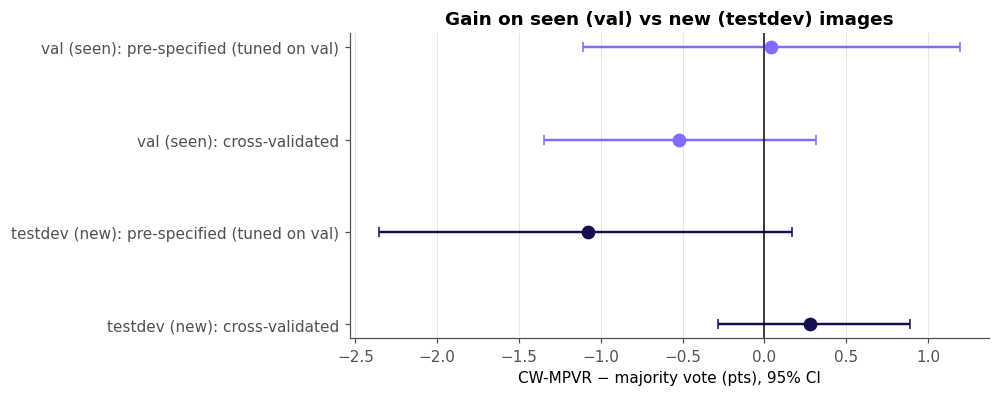

,split,method,A − B (pts),CI low,CI high,only A,only B,p McNemar,p bootstrap
0,val (seen),pre-specified (tuned on val),0.04,-1.1116,1.1966,105,104,1.0000,0.9784
1,val (seen),cross-validated,-0.52,-1.3476,0.3166,48,61,0.2503,0.2232
2,testdev (new),pre-specified (tuned on val),-1.08,-2.3566,0.1670,100,127,0.0842,0.1068
3,testdev (new),cross-validated,0.28,-0.2816,0.8884,30,23,0.4101,0.3668


In [10]:
def within_auc(paths, gold, sig):
    p = paths.assign(ok=paths.answer.values == gold.reindex(paths.id).values)
    vals = []
    for _, d in p.groupby("id"):
        ok = d.ok.values
        if ok.all() or not ok.any():
            continue
        v = d[sig].values
        diff = v[ok][:, None] - v[~ok][None, :]
        vals.append((diff > 0).mean() + 0.5 * (diff == 0).mean())
    return float(np.mean(vals))

mt = read("data/eval_testdev.csv").set_index("id")
GT = mt["answer"].map(P.normalize)
_, PT = A.load_paths("results/paths_eval.jsonl.gz")
auc = pd.DataFrame({"val-eval (seen images)": {s: within_auc(PV, GOLD, s) for s in ["lp_mean", "itm"]},
                    "testdev (new images)": {s: within_auc(PT, GT, s) for s in ["lp_mean", "itm"]}})
auc.index = ["answer confidence", "grounding (ITM)"]
auc.to_csv("results/07_within_auc_seen_vs_new.csv")
display(auc.round(4))

P05 = pd.read_csv("results/05_predictions_eval.csv", dtype=str, keep_default_na=False).set_index("id").reindex(GT.index)
CT = pd.DataFrame({m: P05[m].values == GT.values for m in ["Majority vote", "CW-MPVR (val-tuned)", "CW-MPVR (CV)"]})
IMG_T = mt.loc[GT.index, "imageId"].values
rows = [
    {"split": "val (seen)", "method": "pre-specified (tuned on val)", **PR.compare(CORRECT["CW-MPVR (pre-specified)"], CORRECT["Majority vote"], IMG, SEED)},
    {"split": "val (seen)", "method": "cross-validated", **PR.compare(CORRECT["CW-MPVR (CV)"], CORRECT["Majority vote"], IMG, SEED)},
    {"split": "testdev (new)", "method": "pre-specified (tuned on val)", **PR.compare(CT["CW-MPVR (val-tuned)"], CT["Majority vote"], IMG_T, SEED)},
    {"split": "testdev (new)", "method": "cross-validated", **PR.compare(CT["CW-MPVR (CV)"], CT["Majority vote"], IMG_T, SEED)},
]
seen_new = pd.DataFrame(rows)
seen_new.to_csv("results/07_gain_seen_vs_new.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
yy = np.arange(len(seen_new))[::-1]
col = [VIOLET if "seen" in s else NAVY for s in seen_new.split]
for y_, (_, r), c in zip(yy, seen_new.iterrows(), col):
    ax.errorbar(r["A − B (pts)"], y_, xerr=[[r["A − B (pts)"] - r["CI low"]], [r["CI high"] - r["A − B (pts)"]]],
                fmt="o", color=c, ecolor=c, capsize=3, markersize=8, linewidth=1.6)
ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(yy, [f"{s}: {m}" for s, m in zip(seen_new.split, seen_new.method)])
ax.grid(axis="y", visible=False)
ax.set_xlabel("CW-MPVR − majority vote (pts), 95% CI")
ax.set_title("Gain on seen (val) vs new (testdev) images")
plt.savefig("figures/07_seen_vs_new.png"); plt.show()
seen_new.round(4)

## 8 · Summary (copy this output)

In [11]:
pd.set_option("display.width", 220)
print("=== Accuracy on val-eval (2,500)"); print(table.round(2).to_string())
print("\n=== Tests (Holm)"); print(tests.round(4).to_string(index=False))
print("\n=== CW-MPVR (CV) per repeat"); print(per_rep.round(4).to_string(index=False))
print("\n=== Accuracy by type (val)"); print(acc_t.to_string())
print("\n=== Pre-specified CW-MPVR vs majority by type (val)"); print(gain_t.round(4).to_string(index=False))
print("\n=== Within-question AUC, seen vs new"); print(auc.round(4).to_string())
print("\n=== Gain seen vs new"); print(seen_new.round(4).to_string(index=False))

=== Accuracy on val-eval (2,500)
                         accuracy  ci_low  ci_high  mean of 5 repeats    SD
Greedy                      43.20   41.23    45.18                NaN   NaN
Majority vote               42.64   40.69    44.60                NaN   NaN
Answer-only                 42.80   40.87    44.74                NaN   NaN
CW-MPVR (pre-specified)     42.68   40.71    44.57                NaN   NaN
Answer-only (CV)            42.92   40.97    44.87              42.80  0.16
Grounding-only (CV)         42.72   40.79    44.61              42.81  0.06
CW-MPVR (CV)                42.12   40.18    44.02              42.34  0.17
Oracle                      63.32   61.45    65.11                NaN   NaN

=== Tests (Holm)
                      A                B  A − B (pts)  CI low  CI high  only A  only B  p McNemar  p bootstrap  p McNemar (Holm)  p bootstrap (Holm)
CW-MPVR (pre-specified)           Greedy        -0.52 -1.7249   0.6905     109     122     0.4299       0.4272      

## 9 · Save to GitHub


In [ ]:
save_and_push("notebooks/07_val_protocol.ipynb", "Add proposal protocol: val-balanced evaluation, types, repeated CV, seen vs new images")